In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Contract BT weights — the three big models

The same figure as `baseline_weights_big3`, once for **every contract** we ran on the synthetic laptops
(45 laptops, frame `shopping`, 5 templates, 9900 rows per run). Not the real laptops.

- One figure per contract, one panel per model: qwen-72B, gemma-27B, olmo-32B.
- A model that was never run with a contract gets an empty "not run" panel, so each model is always in the same slot.
- The level(s) the contract asks for are in **bold** on the x-axis.
- Weights are centred to mean 0 inside each feature. Each panel has **its own y-axis**, as in the baseline:
  the size of the weights is not comparable between models (status point 10), only the shape is.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/contract_weights_big3"
os.makedirs(FIGDIR, exist_ok=True)

BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
SCREEN, RAM = ["13-inch", "14-inch", "16-inch"], ["4GB", "8GB", "16GB"]
FEATS = ["brand", "screen", "ram"]
LEVELS = {"brand": BRANDS, "screen": SCREEN, "ram": RAM}
FEATURE_COLOR = {"brand": "#6aa83f", "screen": "#c75f8b", "ram": "#4c8fd4"}   # same colours as figs4nir2
LV = [(f, l) for f in FEATS for l in LEVELS[f]]
LABEL = {l: l.replace("-inch", '"') for _, l in LV}

MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
NAME = {m: f"{m[0]}-{m[1]}B" for m in MODELS}
# gemma-27B's contract runs are split over two folders, so every folder is searched for every model
FOLDERS = ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_olmo"]

## Which contracts we ran

Every complete `shopping` run of the three models with a non-empty contract. The table gives the run folder.

In [3]:
RUNS, CONTRACTS = {}, {}    # (constraints_id, model name) -> run path;  constraints_id -> {feature: level}
for folder in FOLDERS:
    for r in sorted(os.listdir(folder)):
        cf, sc = f"{folder}/{r}/config.json", f"{folder}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue                                   # config without scores = a dead run
        c = json.load(open(cf))
        m = (c["model_family"], str(c["model_size"]))
        if m not in NAME or c["frame"]["name"] != "shopping" or c["constraints"] == {}:
            continue
        key = (c["constraints_id"], NAME[m])
        assert key not in RUNS, key                    # one run per (model, frame, contract)
        RUNS[key] = f"{folder}/{r}"
        CONTRACTS[c["constraints_id"]] = c["constraints"]


def contract_order(cons):
    """Single features first, then pairs, then triples; inside, brand -> screen -> ram, small -> big."""
    return len(cons), [(FEATS.index(f), LEVELS[f].index(cons[f])) for f in FEATS if f in cons]


def short(cons):
    return " + ".join(LABEL[cons[f]] for f in FEATS if f in cons)


CONTRACTS = dict(sorted(CONTRACTS.items(), key=lambda kv: contract_order(kv[1])))
table = pd.DataFrame([{"contract": cid, **{n: RUNS.get((cid, n), "—") for n in NAME.values()}}
                      for cid in CONTRACTS]).set_index("contract")
print(len(CONTRACTS), "contracts,", len(RUNS), "runs")
display(table)

15 contracts, 33 runs


,qwen-72B,gemma-27B,olmo-32B
contract,,,
brand=Apple,—,data/laptops_robustness/1475799,data/laptops_olmo/1475801
brand=Dell,data/laptops_robustness/1445296,data/laptops_robustness/1475800,data/laptops_olmo/1475802
screen=13-inch,data/laptops_robustness/1320495,data/laptops_robustness/1293564,data/laptops_olmo/1475818
screen=14-inch,data/laptops_robustness/68339920,data/laptops_robustness_gemma/68378313,data/laptops_olmo/1320479
screen=16-inch,data/laptops_robustness/1293549,data/laptops_robustness/1293565,data/laptops_olmo/1475819
ram=4GB,data/laptops_robustness/1293550,data/laptops_robustness/1293566,data/laptops_olmo/1475820
ram=8GB,data/laptops_robustness/68374671,data/laptops_robustness_gemma/68378314,data/laptops_olmo/1320480
ram=16GB,data/laptops_robustness/1320496,data/laptops_robustness/1293567,data/laptops_olmo/1475821
brand=Dell+screen=14-inch,data/laptops_robustness/1445303,—,—


## Fit

In [4]:
W, INFO = {}, []
for cid in CONTRACTS:
    for name in NAME.values():
        if (cid, name) not in RUNS:
            continue
        d = pd.read_csv(f"{RUNS[cid, name]}/scores.csv")
        assert len(d) == 9900
        bt = FeatureBT(r2_warn=None).fit(d)
        W[cid, name] = pd.Series({l: bt.weights_[f][l] for f, l in LV})
        INFO.append({"contract": cid, "model": name, "R2": bt.r2_, "beta0": bt.beta0_,
                     "S (total spread)": bt.total_spread(), **{f"range {f}": bt.range(f) for f in FEATS}})

W = pd.DataFrame(W)
W.columns.names = ["contract", "model"]
W.index = pd.MultiIndex.from_tuples(LV, names=["feature", "level"])
W.to_csv(os.path.join(FIGDIR, "contract_weights.csv"))
INFO = pd.DataFrame(INFO).set_index(["contract", "model"])
display(INFO.round(2))

R2  beta0  S (total spread)  \
contract                           model                                      
brand=Apple                        gemma-27B  0.74   4.02             36.99   
                                   olmo-32B   0.91  -1.17             12.29   
brand=Dell                         qwen-72B   0.88  -3.96             35.91   
                                   gemma-27B  0.77   0.65             43.89   
                                   olmo-32B   0.90  -1.32             12.83   
screen=13-inch                     qwen-72B   0.84  -4.92             36.73   
                                   gemma-27B  0.79  -6.74             41.91   
                                   olmo-32B   0.86  -2.01             11.73   
screen=14-inch                     qwen-72B   0.85 -10.91             35.79   
                                   gemma-27B  0.78  -7.36             41.17   
                                   olmo-32B   0.82  -1.49             12.10   
screen=16-inch                     qwen-72B   0.87 -11.06             38.58   
                                   gemma-27B  0.79  -6.88             42.36   
                                   olmo-32B   0.89  -1.18             15.23   
ram=4GB                            qwen-72B   0.77  -9.57             20.20   
                                   gemma-27B  0.60 -11.38             28.36   
                                   olmo-32B   0.84  -2.11              7.83   
ram=8GB                            qwen-72B   0.92  -8.59             29.54   
                                   gemma-27B  0.78  -6.08             32.13   
                                   olmo-32B   0.93  -1.69             11.49   
ram=16GB                           qwen-72B   0.91  -2.42             34.81   
                                   gemma-27B  0.80  -4.63             39.43   
                                   olmo-32B   0.94  -1.45             13.59   
brand=Dell+screen=14-inch          qwen-72B   0.86  -3.89             36.49   
brand=Dell+ram=8GB                 qwen-72B   0.89  -4.33             35.63   
ram=4GB+screen=14-inch             qwen-72B   0.87  -5.88             27.17   
ram=8GB+screen=14-inch             qwen-72B   0.88 -10.49             35.72   
                                   gemma-27B  0.78  -7.96             42.62   
                                   olmo-32B   0.86  -2.04             12.95   
brand=Apple+ram=8GB+screen=14-inch gemma-27B  0.76  -3.06             43.45   
brand=Dell+ram=4GB+screen=14-inch  gemma-27B  0.76  -6.14             41.34   
brand=Dell+ram=8GB+screen=14-inch  qwen-72B   0.86  -3.99             37.14   
                                   gemma-27B  0.77  -3.78             46.27   

                                              range brand  range screen  \
contract                           model                                  
brand=Apple                        gemma-27B        23.53          1.05   
                                   olmo-32B          8.67          0.12   
brand=Dell                         qwen-72B         22.06          1.38   
                                   gemma-27B        27.57          2.01   
                                   olmo-32B          8.35          0.34   
screen=13-inch                     qwen-72B          0.96         21.12   
                                   gemma-27B         1.93         26.31   
                                   olmo-32B          0.20          7.55   
screen=14-inch                     qwen-72B          0.95         18.79   
                                   gemma-27B         1.35         25.89   
                                   olmo-32B          0.95          6.38   
screen=16-inch                     qwen-72B          0.66         22.41   
                                   gemma-27B         2.04         25.01   
                                   olmo-32B          1.21          8.43   
ram=4GB                            qwen-72B          5.01          2.37   
       

## The figures

brand=Apple


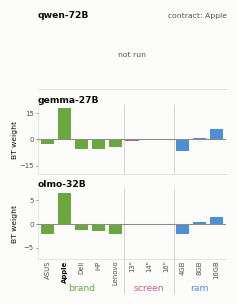

brand=Dell


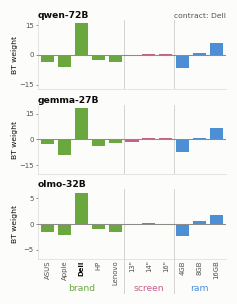

screen=13-inch


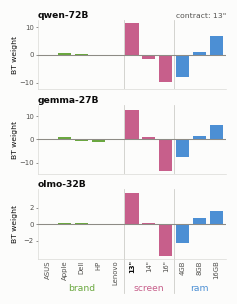

screen=14-inch


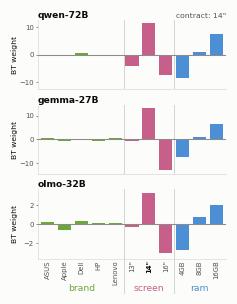

screen=16-inch


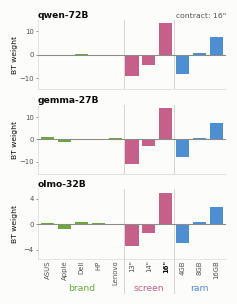

ram=4GB


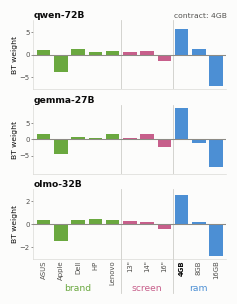

ram=8GB


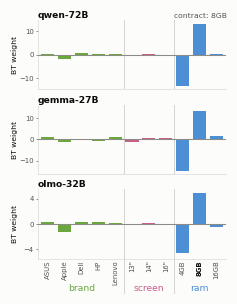

ram=16GB


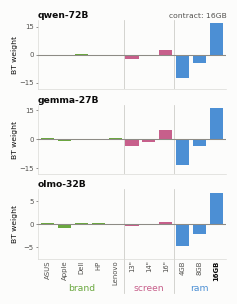

brand=Dell+screen=14-inch


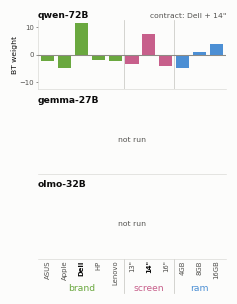

brand=Dell+ram=8GB


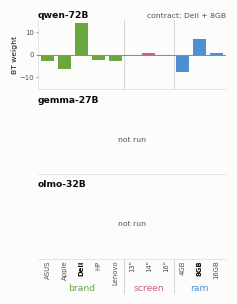

ram=4GB+screen=14-inch


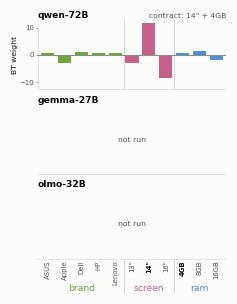

ram=8GB+screen=14-inch


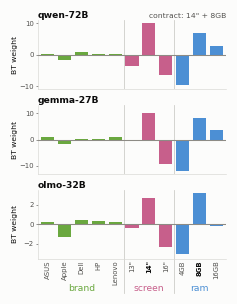

brand=Apple+ram=8GB+screen=14-inch


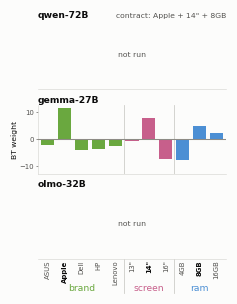

brand=Dell+ram=4GB+screen=14-inch


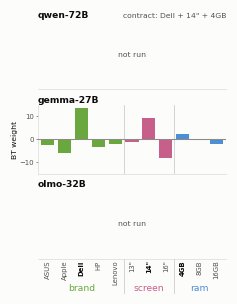

brand=Dell+ram=8GB+screen=14-inch


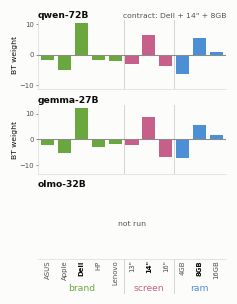

In [5]:
def nice_tick(v):
    """Biggest round number that is not above v."""
    return max(t for t in [0.5, 1, 2, 4, 5, 10, 15, 20, 30] if t <= v)


def fig_weights(cid):
    cons = CONTRACTS[cid]
    names = list(NAME.values())
    fig, axes = plt.subplots(len(names), 1, figsize=(2, 0.875 * len(names)), sharex=True)
    x = np.arange(len(LV))
    ran = [(cid, name) in W for name in names]
    for ax, name, ok in zip(axes, names, ran):
        ax.set_title(name, loc="left", fontsize=6, fontweight="bold", pad=1.5)
        ax.tick_params(axis="x", length=0, pad=1)
        ax.spines["bottom"].set_linewidth(0.4)
        ax.set_xlim(-0.6, len(LV) - 0.4)
        if not ok:                                         # this model never ran this contract
            ax.text(0.5, 0.5, "not run", transform=ax.transAxes, ha="center", va="center", fontsize=5,
                    color=INK_MUTED)
            ax.set_yticks([])
            ax.spines["left"].set_visible(False)
            continue
        w = W[cid, name].values
        top = np.abs(w).max()
        ax.bar(x, w, 0.78, color=[FEATURE_COLOR[f] for f, _ in LV], zorder=2)
        ax.axhline(0, color="#8d8b85", lw=0.7, zorder=3)
        ax.set_ylabel("BT weight", fontsize=5, labelpad=1)
        ax.set_ylim(-1.1 * top, 1.1 * top)                 # own scale per model
        t = nice_tick(top)
        ax.set_yticks([-t, 0, t])
        ax.tick_params(axis="y", labelsize=4.5, length=1.5, width=0.4, pad=1, colors=INK_MUTED)
        ax.spines["left"].set_linewidth(0.4)
    axes[0].text(1, 1.02, f"contract: {short(cons)}", transform=axes[0].transAxes, ha="right", va="bottom",
                 fontsize=5, color=INK_MUTED)
    axes[-1].set_xticks(x, [LABEL[l] for _, l in LV], rotation=90, fontsize=4.5, color=INK_MUTED)
    for tick, (f, l) in zip(axes[-1].get_xticklabels(), LV):
        if cons.get(f) == l:                               # the level the contract asks for
            tick.set_fontweight("bold")
            tick.set_color(INK)
    fig.tight_layout(h_pad=0.4, pad=0.15, rect=(0, 0.035, 1, 1))
    fig.align_ylabels(axes)
    for k in (5, 8):
        for ax, ok in zip(axes, ran):
            if ok:
                ax.axvline(k - 0.5, color="#c9c8c3", lw=0.5, zorder=1)
        axes[-1].plot([k - 0.5, k - 0.5], [0, -0.5], transform=axes[-1].get_xaxis_transform(), color="#c9c8c3",
                      lw=0.5, clip_on=False)
    for f, (a, b) in zip(FEATS, [(0, 4), (5, 7), (8, 10)]):
        axes[-1].text((a + b) / 2, -0.43, f, transform=axes[-1].get_xaxis_transform(), ha="center",
                      va="center", fontsize=6, color=FEATURE_COLOR[f])
    fig.savefig(os.path.join(FIGDIR, f"{cid}.png"), facecolor=SURFACE, dpi=400)
    fig.savefig(os.path.join(FIGDIR, f"{cid}.pdf"), facecolor=SURFACE)
    plt.show()


for cid in CONTRACTS:
    print(cid)
    fig_weights(cid)